# Lab 7_1: Numerical_calculus -> Derivation

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy import interpolate
import scipy.integrate as integrate


## Derivation

### <font color='red'>     **Activity: Hecho en el notebook** </font>

Fourier's Law of thermal conduction describes the diffusion of heat. Situations in which there are gradients of heat, a flux that tends to homogenise the temperature arises as a consequence of collisions of particles within a body. The Fourier's Law is giving by

$$ q = -k\nabla T = -k\left( \frac{dT}{dx}\hat{i} + \frac{dT}{dy}\hat{j} + \frac{dT}{dz}\hat{k}\right)$$

where T is the temperature, $\nabla T$ its gradient and k is the material's conductivity. In the next example it is shown the magnitud of the heat flux.
- - -
Consider the temperature profile as
$$ T(x,y) = x^3 + 3x-1+y^2  $$

Compute the derivatiuve in $x$ and $y$ and compare with the analytical derivative in x and y.

In [ ]:
right = 0
(-1)**right*2
def TEP( Yn,i, h, right=0 ): #Yn:funcion, i:punto, h:tendencia a cero
    suma = -3*Yn[i]+4*Yn[i+(-1)**right*1]-Yn[i+(-1)**right*2]
    return suma/(2*h*(-1)**right)
def T(x,y):
  return x**3+3*x-1+y**2
xn = [T(4,5),T(5,5),T(6,5)]
yn = [T(5,5),T(5,6),T(5,7)]
def dx(x):
  return 3*x**2+3
def dy(y):
  return 2*y
h = 1
print(TEP(xn,0,h),dx(4))
print(TEP(yn,0,h),dy(5))

49.0 51
10.0 10


### <font color='red'>     **Activity 1** </font>

Consider the next lists for $x_n$ and $y_n$.

* Build the numerical derivative.
* Interpole the data. Interpole the found numerical derivative, next do the integral and find the original polinomial. What conclude?

In [ ]:
x = [0.        , 0.26315789, 0.52631579, 0.78947368, 1.05263158,
       1.31578947, 1.57894737, 1.84210526, 2.10526316, 2.36842105,
       2.63157895, 2.89473684, 3.15789474, 3.42105263, 3.68421053,
       3.94736842, 4.21052632, 4.47368421, 4.73684211, 5.        ]
y = [ 1.        ,  1.06925208,  1.27700831,  1.6232687 ,  2.10803324,
        2.73130194,  3.49307479,  4.3933518 ,  5.43213296,  6.60941828,
        7.92520776,  9.37950139, 10.97229917, 12.70360111, 14.5734072 ,
       16.58171745, 18.72853186, 21.01385042, 23.43767313, 26.        ]

Text(0, 0.5, 'dy/dx')

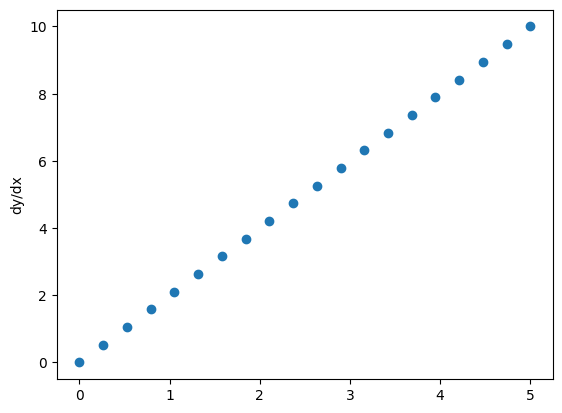

In [ ]:
from scipy.interpolate import CubicSpline
xmax = x[-1]
xmin = x[0]
nps = len(x)-1
def TMP( Ynh,Ynmh, h ):
    return (Ynh-Ynmh)/(2*h)
h= (xmax-xmin)/nps
Q = []
Q.append(TEP(y,0,h))
index = len(x)-1
for i in range(1,index):
  Q.append(TMP(y[i+1],y[i-1],h))
Q.append(TEP(y,index,h,right=1))
derivada = CubicSpline(x, Q, bc_type='natural')
plt.scatter(x,derivada(x))
plt.ylabel("dy/dx")

integral de: 65.37499998430002


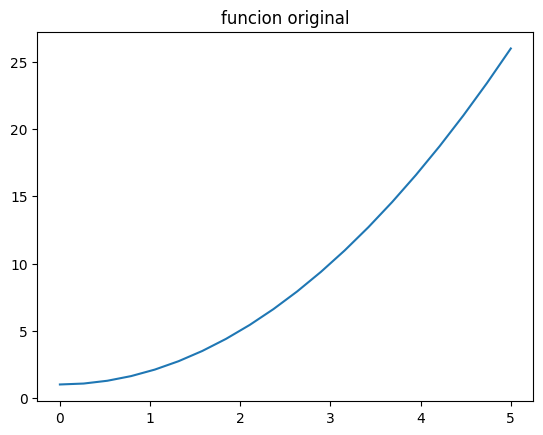

In [ ]:
def trape_compu(f,a,b,N):
  x = np.linspace(a,b,N)
  h = (b-a)/N
  suma = 0
  for i in range(N):
    suma += f(x[i])
  return (f(a)+2*suma+f(b))*h/2
funcion = CubicSpline(x,y)
integral = trape_compu(funcion,x[0],x[-1],5)
plt.title("funcion original")
plt.plot(x,funcion(x))
print("integral de:",integral)

In [ ]:
#no solo es graficar. no concluye. falto construir la interpolación.
P1 = 30

### <font color='red'>     **Activity 2** </font>

The radar stations A and B, separated by the distance a = 500 m, track the plane
C by recording the angles $\alpha$ and $\beta$ at 1-second intervals. The successive readings are

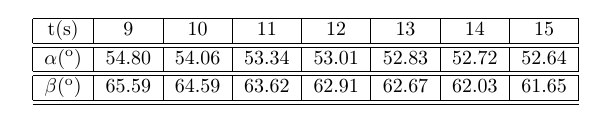

In [ ]:
from IPython.display import Image
Image("https://raw.githubusercontent.com/sbustamante/ComputationalMethods/refs/heads/master/material/figures/table.png")

calculate the speed v using the 3 point approximantion at t = 10 ,12 and 14 s. Calculate the x component of the acceleration of the plane at = 12 s. The coordinates of the plane can be shown to be

\begin{equation}
x = a\frac{\tan \beta}{\tan \beta- \tan \alpha}\\
y = a\frac{\tan \alpha\tan \beta}{\tan \beta- \tan \alpha}
\end{equation}


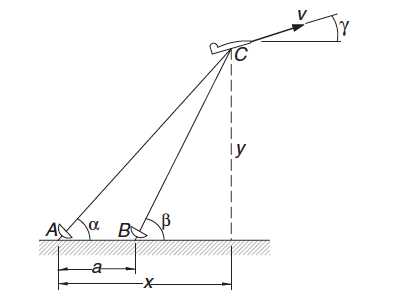

In [ ]:
from IPython.display import Image
Image("https://raw.githubusercontent.com/sbustamante/ComputationalMethods/refs/heads/master/material/figures/radar.png")

In [ ]:
def TEP(Yn, i, h):
    n = len(Yn)
    if i == 0:
        return (-3*Yn[i] + 4*Yn[i+1] - Yn[i+2]) / (2*h)
    elif i == n-1:
        return (3*Yn[i] - 4*Yn[i-1] + Yn[i-2]) / (2*h)
    else:
        return (Yn[i+1] - Yn[i-1]) / (2*h)

a = 500
t = [9, 10, 11, 12, 13, 14, 15]
alfa = [54.80, 54.06, 53.34, 53.01, 52.83, 52.72, 52.64]   # grados
beta = [65.59, 64.59, 63.62, 62.91, 62.67, 62.03, 61.65]   # grados
alfa_rad = np.radians(alfa)
beta_rad = np.radians(beta)
def x(a,al,be):
  return a*np.tan(be)/(np.tan(be)-np.tan(al))
def y(a,al,be):
  return a*np.tan(be)*np.tan(al)/(np.tan(be)-np.tan(al))
X = []
Y = []
for i in range(len(t)):
  X.append(x(a,alfa_rad[i],beta_rad[i]))
  Y.append(y(a,alfa_rad[i],beta_rad[i]))
h = (t[1]-t[0])
ax = (X[2]-2*X[3]+X[4])/(h**2)
print("velocidad en x t=10",TEP(X,1,h))
print("velocidad en y t=10",TEP(Y,1,h))
print("velocidad en x t=12",TEP(X,3,h))
print("velocidad en y t=12",TEP(Y,3,h))
print("velocidad en x t=14",TEP(X,5,h))
print("velocidad en y t=14",TEP(Y,5,h))
print("Aceleración en x", ax)

velocidad en x t=10 48.36097598564345
velocidad en y t=10 13.083197366050399
velocidad en x t=12 35.86048963910662
velocidad en y t=12 28.806586171293247
velocidad en x t=14 67.33788263946906
velocidad en y t=14 81.09999625321052
Aceleración en x -46.62665212228376


Text(0, 0.5, 'altura (m)')

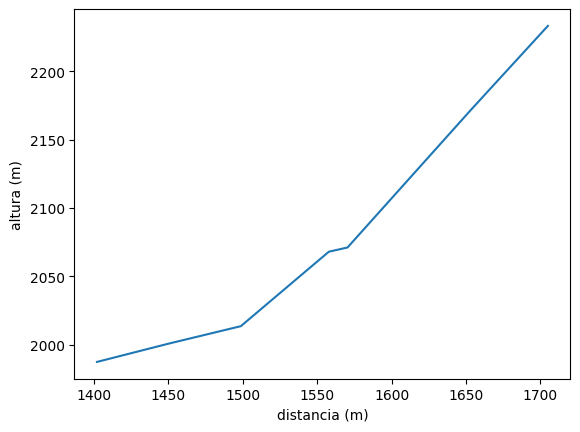

In [ ]:
plt.plot(X,Y)
plt.xlabel("distancia (m)")
plt.ylabel("altura (m)")

In [ ]:
#velociades son 50, 46, 105. aceleración -2
P2 = 30

In [ ]:
print('puntos:',P1+P2)
print('nota:',(P1+P2)*5/100)

puntos: 60
nota: 3.0
